# Okun's Law Across Countries: Growth, Unemployment and the Labour Market

**Research question:** how much does unemployment respond to economic growth in the US and in Europe, has this relationship changed over time, and what does it tell us about the labour market today?

Okun's law is one of the most used rules of thumb in macroeconomics: when growth falls below its normal pace, unemployment rises. Strategists and central banks use it to translate GDP forecasts into unemployment forecasts, and to check whether the labour market is behaving "normally" for the growth it is getting.

The notebook is organised in seven steps:

1. **Data**: quarterly real GDP and unemployment for the US, the euro area, Germany, France, Italy, Spain and Denmark
2. **Okun's law by country**: how strongly unemployment reacts to growth, and how much growth is needed to keep unemployment stable
3. **Gap version (US)**: the link between the unemployment gap and the output gap
4. **Stability over time**: rolling estimates, before and after the 2008 crisis
5. **Today's labour market**: is unemployment higher or lower than growth would imply?
6. **Scenarios**: the unemployment change implied by different growth outcomes
7. **Automatic export**: README, charts and tables zipped and ready for GitHub

**How to use it:** check the settings in the first code cell, then *Runtime → Run all*. At the end a zip file with everything for GitHub is downloaded automatically.

> Research and educational project. Not investment advice.

In [1]:
# ============================================================================
# SETTINGS: change these before running
# ============================================================================
AUTHOR = "Mattia Mariani"
GITHUB_USERNAME = "gabsmm18"
REPO_NAME = "okun-law-analysis"
NOTEBOOK_NAME = "okun_law_analysis.ipynb"

In [2]:
import io
import os
import shutil
import warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

# --- Model parameters -------------------------------------------------------
SAMPLE_START = "2000Q1"                  # common estimation start for all countries
COVID = ("2020Q1", "2021Q4")             # excluded from the estimates (see Step 2)
ROLLING_WINDOW = 40                      # quarters (10 years) for rolling estimates
PRE_CRISIS_END, POST_CRISIS_START = "2007Q4", "2010Q1"

COUNTRIES = {
    # name: (ECB code, FRED GDP id, colour)
    "United States": (None, "GDPC1", "#1f4e79"),
    "Euro area": ("I9", None, "#c47f00"),
    "Germany": ("DE", "CLVMNACSCAB1GQDE", "#333333"),
    "France": ("FR", "CLVMNACSCAB1GQFR", "#2e7d32"),
    "Italy": ("IT", "CLVMNACSCAB1GQIT", "#7b1fa2"),
    "Spain": ("ES", "CLVMNACSCAB1GQES", "#c62828"),
    "Denmark": ("DK", "CLVMNACSCAB1GQDK", "#00838f"),
}
NAMES = list(COUNTRIES)
COLORS = {k: v[2] for k, v in COUNTRIES.items()}

# --- Output folders (everything inside OUT is what goes on GitHub) ----------
OUT = "github_export"
FIG = f"{OUT}/figures"
TAB = f"{OUT}/tables"
for d in (FIG, TAB):
    os.makedirs(d, exist_ok=True)


def save(fig, name):
    fig.savefig(f"{FIG}/{name}", dpi=150, bbox_inches="tight")

## Step 1: Data

| Variable | United States | Europe |
|---|---|---|
| Real GDP | FRED (BEA), seasonally adjusted | Eurostat via FRED, with the ECB Data Portal as backup |
| Unemployment rate | FRED (BLS), seasonally adjusted | ECB Data Portal (Eurostat harmonised rate, age 15-74), seasonally adjusted |
| Output gap and natural rate (US only) | CBO potential GDP and natural rate of unemployment | |

From these we build the two variables of Okun's law:

- **growth** = % change in real GDP over the last 4 quarters;
- **change in unemployment** = change in the unemployment rate over the last 4 quarters, in percentage points.

Using 4-quarter changes instead of quarter-on-quarter changes removes most of the noise in quarterly data. Monthly unemployment is averaged to quarters. Everything is downloaded automatically and no API key is needed.

In [3]:
def fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".")
    return df.iloc[:, 0].astype(float).dropna()


def _parse_dates(periods):
    periods = periods.astype(str)
    if periods.str.contains("-Q").any():
        return pd.PeriodIndex(periods.str.replace("-Q", "Q"), freq="Q").to_timestamp()
    return pd.to_datetime(periods)


def ecb(key):
    flow, series = key.split("/", 1)
    r = requests.get(f"https://data-api.ecb.europa.eu/service/data/{flow}/{series}",
                     params={"format": "csvdata"}, timeout=60)
    r.raise_for_status()
    df = pd.read_csv(io.StringIO(r.text))
    s = pd.Series(pd.to_numeric(df["OBS_VALUE"], errors="coerce").values, index=_parse_dates(df["TIME_PERIOD"]))
    return s.dropna().sort_index()


def first_available(*loaders):
    # Try several sources in order and return the first that works
    errors = []
    for name, load in loaders:
        try:
            s = load()
            if len(s) > 20:
                return s
            errors.append(f"  {name}: too few observations")
        except Exception as e:
            errors.append(f"  {name}: {e}")
    raise RuntimeError("All sources failed:\n" + "\n".join(errors))


def quarterly(s):
    return s.resample("QS").mean().to_period("Q")


def load_country(name):
    code, fred_gdp, _ = COUNTRIES[name]
    if name == "United States":
        gdp, unemp = fred("GDPC1"), fred("UNRATE")
    else:
        gdp_sources = []
        if fred_gdp:
            gdp_sources.append(("FRED " + fred_gdp, lambda: fred(fred_gdp)))
        gdp_sources += [(f"ECB MNA {c}", (lambda c=c: ecb(f"MNA/Q.Y.{c}.W2.S1.S1.B.B1GQ._Z._Z._Z.{u}.LR.N")))
                        for c in ([code, "I10"] if code == "I9" else [code]) for u in ("EUR", "XDC")]
        if name == "Euro area":
            gdp_sources.append(("FRED EA19", lambda: fred("CLVMNACSCAB1GQEA19")))
        gdp = first_available(*gdp_sources)
        areas = ["I9", "I10", "U2"] if code == "I9" else [code]
        unemp = first_available(*[(f"ECB LFSI {a}", (lambda a=a: ecb(f"LFSI/M.{a}.S.UNEHRT.TOTAL0.15_74.T")))
                                  for a in areas])
    df = pd.DataFrame({"gdp": quarterly(gdp), "unemployment": quarterly(unemp)})
    df["growth"] = 100 * (np.log(df["gdp"]) - np.log(df["gdp"].shift(4)))     # % over 4 quarters
    df["d_unemployment"] = df["unemployment"] - df["unemployment"].shift(4)   # pp over 4 quarters
    df["covid"] = (df.index >= pd.Period(COVID[0])) & (df.index <= pd.Period(COVID[1]))
    return df


data = {}
for name in NAMES:
    try:
        data[name] = load_country(name)
        d = data[name].dropna(subset=["growth", "d_unemployment"])
        print(f"{name:15s} {d.index[0]} -> {d.index[-1]}")
    except RuntimeError as e:
        print(f"{name}: SKIPPED, data not available\n{e}")
NAMES = [n for n in NAMES if n in data]

# US gap data (CBO)
us = data["United States"]
us["output_gap"] = quarterly(100 * (fred("GDPC1") / fred("GDPPOT") - 1))
us["unemployment_gap"] = us["unemployment"] - quarterly(fred("NROU"))

United States   1949Q1 -> 2026Q3
Euro area       2001Q1 -> 2026Q1
Germany         1992Q1 -> 2026Q3
France          1984Q1 -> 2026Q3
Italy           1997Q1 -> 2026Q3
Spain           1996Q1 -> 2026Q3
Denmark         1996Q1 -> 2026Q2


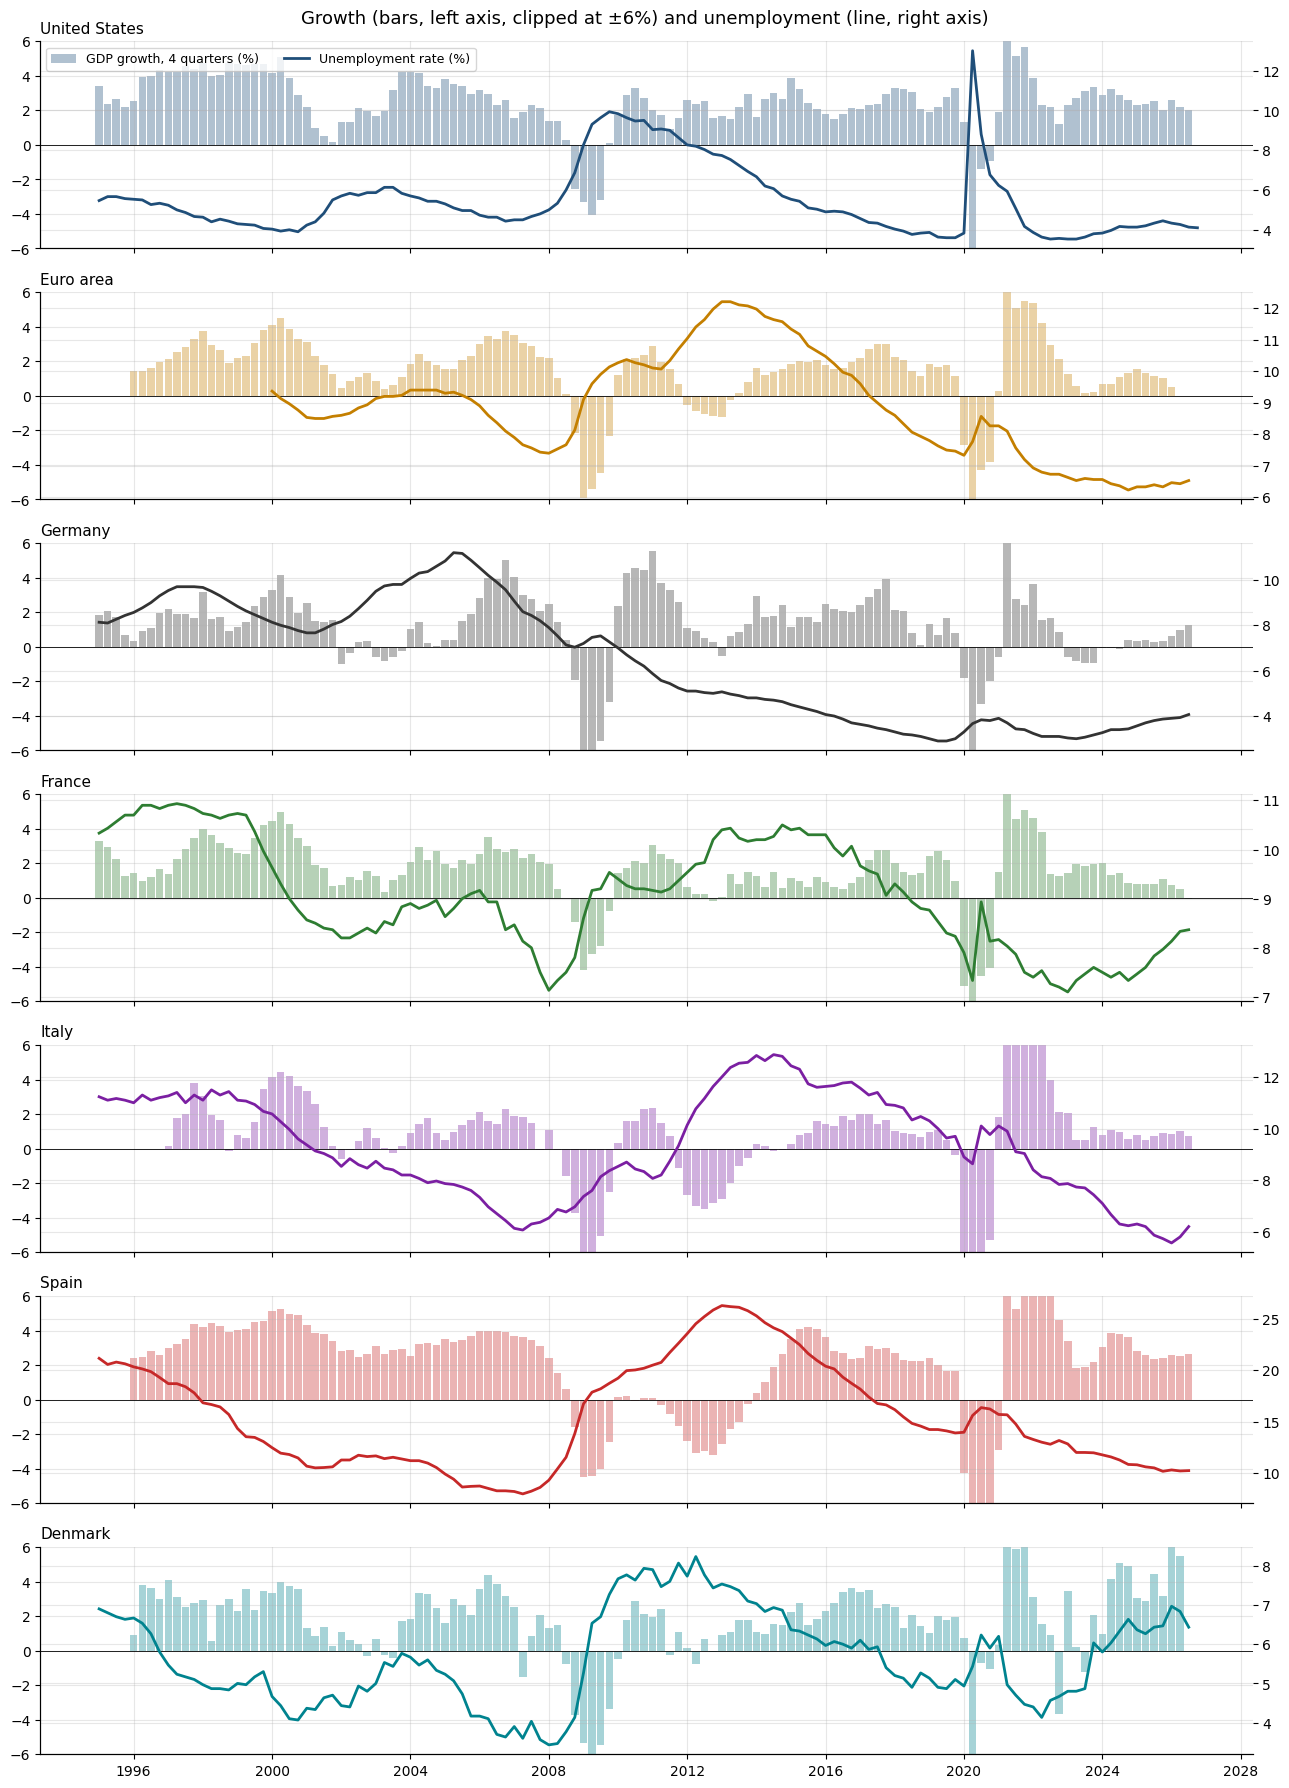

In [4]:
# Chart: growth and unemployment by country
fig, axes = plt.subplots(len(NAMES), 1, figsize=(13, 2.6 * len(NAMES)), sharex=True)
for ax, name in zip(axes, NAMES):
    d = data[name].loc["1995Q1":]
    t = d.index.to_timestamp()
    ax.bar(t, d["growth"], width=80, color=COLORS[name], alpha=0.35, label="GDP growth, 4 quarters (%)")
    ax2 = ax.twinx()
    ax2.plot(t, d["unemployment"], color=COLORS[name], lw=2, label="Unemployment rate (%)")
    ax2.spines["top"].set_visible(False)
    ax.set_ylim(-6, 6)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(name, loc="left", fontsize=11)
    if name == NAMES[0]:
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, loc="upper left", ncol=2, fontsize=9)
fig.suptitle("Growth (bars, left axis, clipped at ±6%) and unemployment (line, right axis)", fontsize=13)
fig.tight_layout()
save(fig, "01_growth_and_unemployment.png")
plt.show()

## Step 2: Okun's law by country

We estimate the **difference version** of Okun's law:

$$\Delta u_t = a + b\, g_t + \varepsilon_t$$

- $\Delta u_t$ is the change in the unemployment rate over 4 quarters, $g_t$ GDP growth over 4 quarters;
- $b$ is the **Okun coefficient**: how many percentage points unemployment changes for each extra point of growth. It is negative. Okun's original estimate for the US was about −0.3 to −0.5;
- $g^* = -a/b$ is the **growth rate that keeps unemployment stable**. When growth is above $g^*$, unemployment falls. It is a rough estimate of the economy's potential growth.

**Why exclude 2020-2021?** During COVID GDP collapsed and rebounded within months, while unemployment in Europe barely moved because of job-retention schemes (short-time work), and in the US it jumped and then fell back. These extreme points would dominate the regression and distort the normal relationship, so they are excluded and shown separately in the charts.

Standard errors are robust to autocorrelation (HAC), which is needed because overlapping 4-quarter changes are mechanically correlated.

In [5]:
def okun(df, start=SAMPLE_START, end=None, exclude_covid=True):
    d = df.loc[start:end].dropna(subset=["growth", "d_unemployment"])
    if exclude_covid:
        d = d[~d["covid"]]
    X = sm.add_constant(d["growth"])
    m = sm.OLS(d["d_unemployment"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    a, b = m.params["const"], m.params["growth"]
    V = m.cov_params()
    grad = np.array([-1 / b, a / b ** 2])               # delta method for g* = -a/b
    g_star_se = float(np.sqrt(grad @ V.values @ grad))
    return {"quarters": int(m.nobs), "okun_b": b, "okun_b_se": m.bse["growth"],
            "a": a, "g_star": -a / b, "g_star_se": g_star_se, "r2": m.rsquared, "model": m,
            "start": str(d.index[0]), "end": str(d.index[-1])}


results = {name: okun(data[name]) for name in NAMES}
okun_table = pd.DataFrame({n: {k: v for k, v in r.items() if k != "model"} for n, r in results.items()}).T
okun_table = okun_table.sort_values("okun_b")
okun_table[["quarters", "okun_b", "okun_b_se", "g_star", "g_star_se", "r2"]].astype(float).to_csv(
    f"{TAB}/okun_coefficients.csv")
display(okun_table[["start", "end", "quarters", "okun_b", "okun_b_se", "g_star", "g_star_se", "r2"]])

,start,end,quarters,okun_b,okun_b_se,g_star,g_star_se,r2
Spain,2000Q1,2026Q3,99,-0.77,0.12,1.91,0.34,0.69
United States,2000Q1,2026Q3,99,-0.51,0.09,2.08,0.27,0.51
Euro area,2001Q1,2026Q1,93,-0.37,0.04,0.97,0.24,0.70
France,2000Q1,2026Q3,99,-0.31,0.04,1.26,0.27,0.47
Italy,2000Q1,2026Q3,99,-0.30,0.07,0.04,0.48,0.51
Denmark,2000Q1,2026Q2,98,-0.20,0.08,1.88,0.70,0.24
Germany,2000Q1,2026Q3,99,-0.15,0.07,-0.16,1.23,0.24


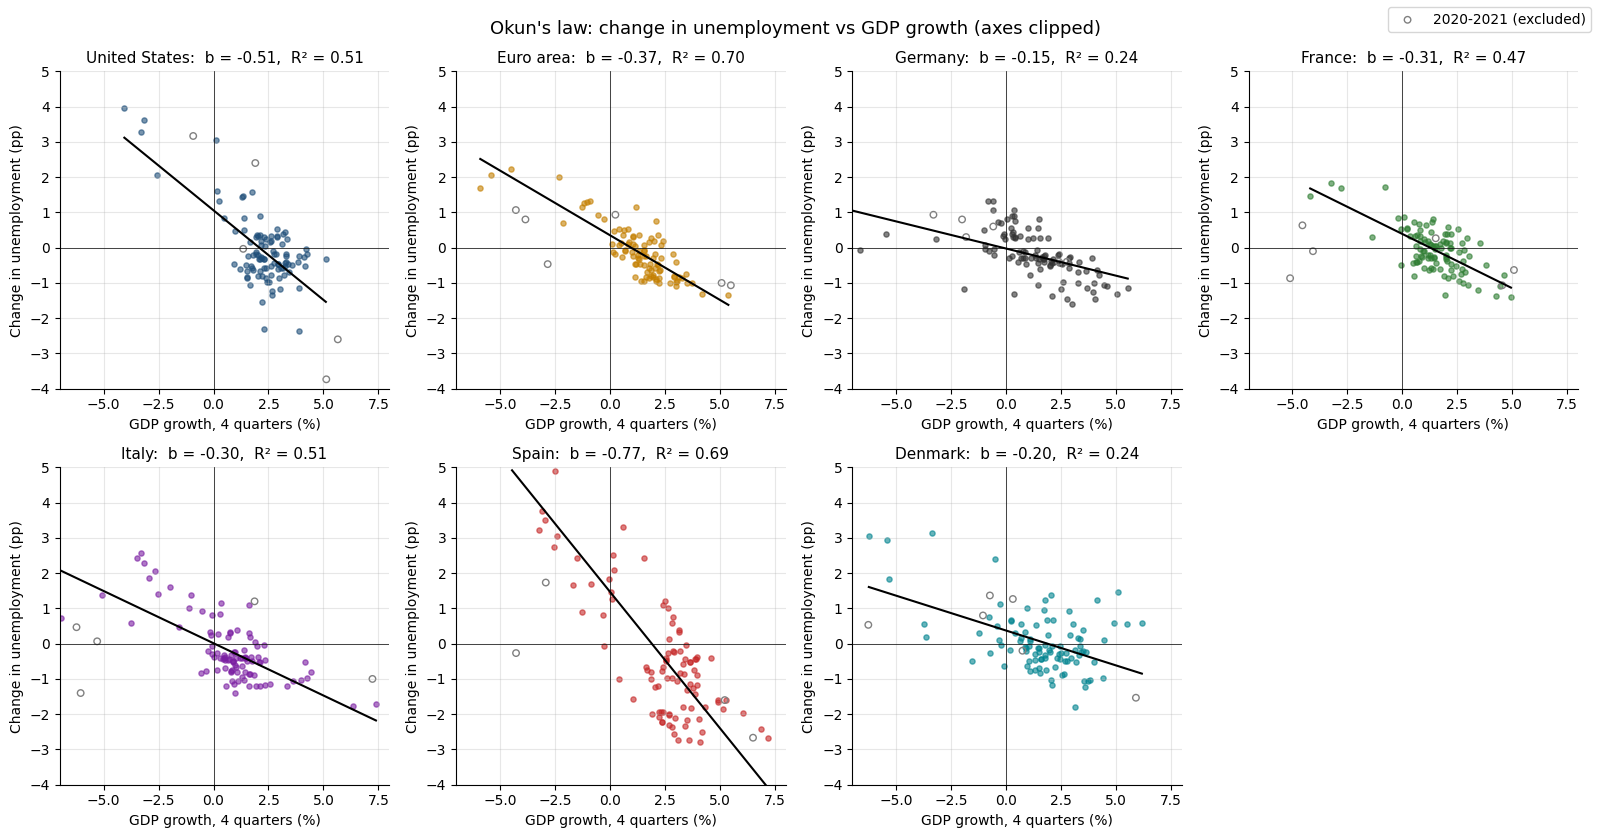

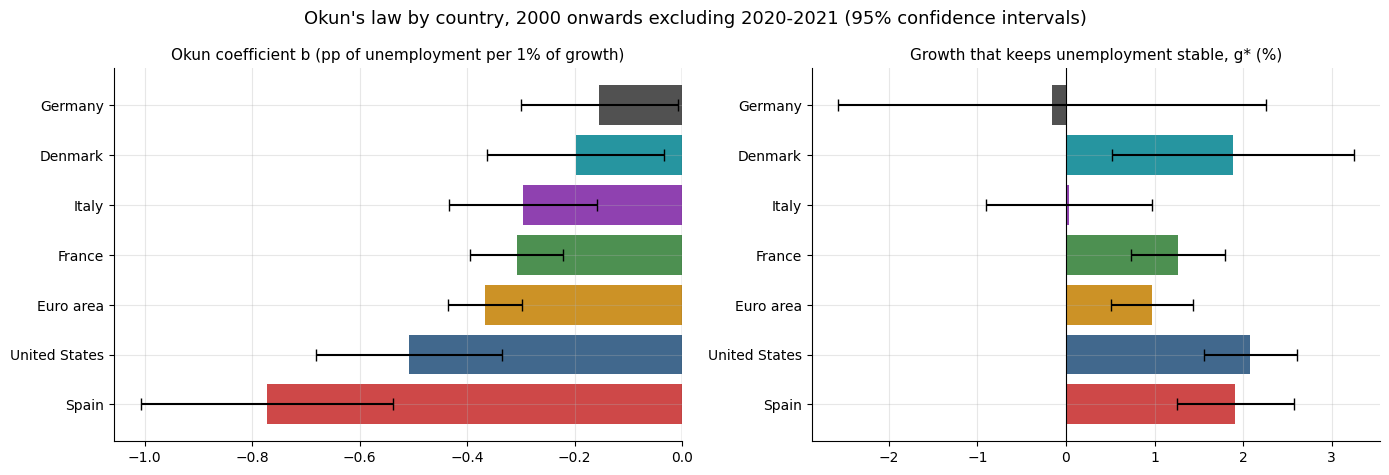

In [6]:
# Scatter plots with fitted line, COVID quarters highlighted
ncol = 4
nrow = int(np.ceil(len(NAMES) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 4.2 * nrow))
axes = list(axes.flat)
for ax, name in zip(axes, NAMES):
    d = data[name].loc[SAMPLE_START:].dropna(subset=["growth", "d_unemployment"])
    normal, covid = d[~d["covid"]], d[d["covid"]]
    ax.scatter(normal["growth"], normal["d_unemployment"], s=14, color=COLORS[name], alpha=0.6)
    ax.scatter(covid["growth"], covid["d_unemployment"], s=22, facecolors="none", edgecolors="grey",
               label="2020-2021 (excluded)")
    r = results[name]
    x = np.linspace(normal["growth"].min(), normal["growth"].max(), 50)
    ax.plot(x, r["a"] + r["okun_b"] * x, color="black", lw=1.5)
    ax.axhline(0, color="black", lw=0.5)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_xlim(-7, 8)
    ax.set_ylim(-4, 5)
    ax.set_title(f"{name}:  b = {r['okun_b']:.2f},  R² = {r['r2']:.2f}", fontsize=11)
    ax.set_xlabel("GDP growth, 4 quarters (%)")
    ax.set_ylabel("Change in unemployment (pp)")
for ax in axes[len(NAMES):]:
    ax.set_visible(False)
fig.legend(*fig.axes[0].get_legend_handles_labels(), loc="upper right")
fig.suptitle("Okun's law: change in unemployment vs GDP growth (axes clipped)", fontsize=13)
fig.tight_layout()
save(fig, "02_okun_scatter.png")
plt.show()

# Bar chart of coefficients and stable-unemployment growth
order = okun_table.index
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (col, title) in zip(axes, [("okun_b", "Okun coefficient b (pp of unemployment per 1% of growth)"),
                                   ("g_star", "Growth that keeps unemployment stable, g* (%)")]):
    vals = okun_table[col].astype(float)
    ses = okun_table[col + "_se"].astype(float)
    ax.barh(order, vals, xerr=1.96 * ses, color=[COLORS[n] for n in order], alpha=0.85, capsize=4)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(title, fontsize=11)
fig.suptitle("Okun's law by country, 2000 onwards excluding 2020-2021 (95% confidence intervals)", fontsize=13)
fig.tight_layout()
save(fig, "03_okun_coefficients.png")
plt.show()

## Step 3: Gap version (United States)

Okun's original formulation links **levels**, not changes:

$$u_t - u^*_t = \beta\,(y_t - y^*_t) + \varepsilon_t$$

where $u^*$ is the natural rate of unemployment and $y - y^*$ the output gap, both estimated by the Congressional Budget Office (CBO). A coefficient around −0.5 means that when GDP is 2% above potential, unemployment is about 1 point below its natural rate.

This version is useful because it lets us **translate between the labour market and the output gap**. The output gap cannot be observed, while unemployment is measured every month. This is why central banks often use the unemployment gap as a real-time proxy for the output gap, for example in a Taylor rule.

Gap version (US): beta = -0.82 (s.e. 0.09), R² = 0.80, 99 quarters


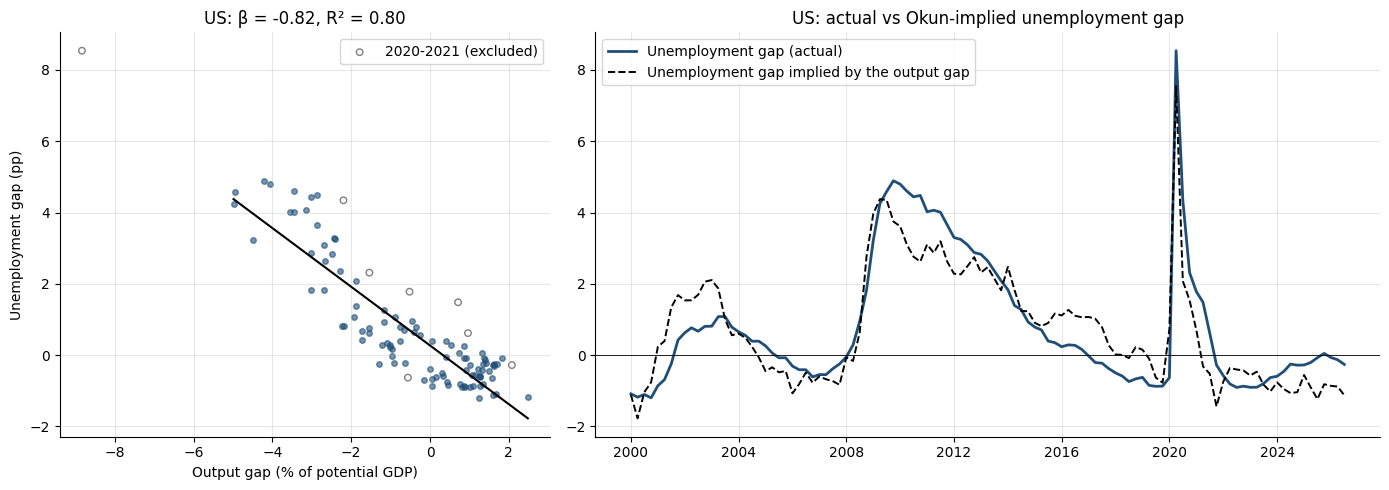

In [7]:
g = us.loc[SAMPLE_START:].dropna(subset=["output_gap", "unemployment_gap"])
g_fit = g[~g["covid"]]
gap_model = sm.OLS(g_fit["unemployment_gap"], sm.add_constant(g_fit["output_gap"])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 4})
gap_beta, gap_beta_se, gap_r2 = gap_model.params["output_gap"], gap_model.bse["output_gap"], gap_model.rsquared
pd.DataFrame({"beta": [gap_beta], "se": [gap_beta_se], "r2": [gap_r2], "quarters": [int(gap_model.nobs)]},
             index=["US gap version"]).to_csv(f"{TAB}/okun_gap_version_us.csv")
print(f"Gap version (US): beta = {gap_beta:.2f} (s.e. {gap_beta_se:.2f}), R² = {gap_r2:.2f}, {int(gap_model.nobs)} quarters")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.scatter(g_fit["output_gap"], g_fit["unemployment_gap"], s=16, color=COLORS["United States"], alpha=0.6)
cv = g[g["covid"]]
ax.scatter(cv["output_gap"], cv["unemployment_gap"], s=22, facecolors="none", edgecolors="grey", label="2020-2021 (excluded)")
x = np.linspace(g_fit["output_gap"].min(), g_fit["output_gap"].max(), 50)
ax.plot(x, gap_model.params["const"] + gap_beta * x, color="black")
ax.set_xlabel("Output gap (% of potential GDP)")
ax.set_ylabel("Unemployment gap (pp)")
ax.set_title(f"US: β = {gap_beta:.2f}, R² = {gap_r2:.2f}")
ax.legend()
ax = axes[1]
t = g.index.to_timestamp()
ax.plot(t, g["unemployment_gap"], color=COLORS["United States"], lw=2, label="Unemployment gap (actual)")
ax.plot(t, gap_model.params["const"] + gap_beta * g["output_gap"], color="black", lw=1.4, ls="--",
        label="Unemployment gap implied by the output gap")
ax.axhline(0, color="black", lw=0.6)
ax.set_title("US: actual vs Okun-implied unemployment gap")
ax.legend()
fig.tight_layout()
save(fig, "04_us_gap_version.png")
plt.show()

## Step 4: Is Okun's law stable over time?

A single coefficient for 25 years hides a lot. We re-estimate the Okun coefficient on **rolling 10-year windows** (40 quarters), and compare the decade before the 2008 crisis with the period after it.

If the coefficient becomes more negative, unemployment has become **more sensitive** to growth (for example because of more flexible labour markets). If it moves towards zero, firms adjust less through jobs and more through hours worked or productivity.

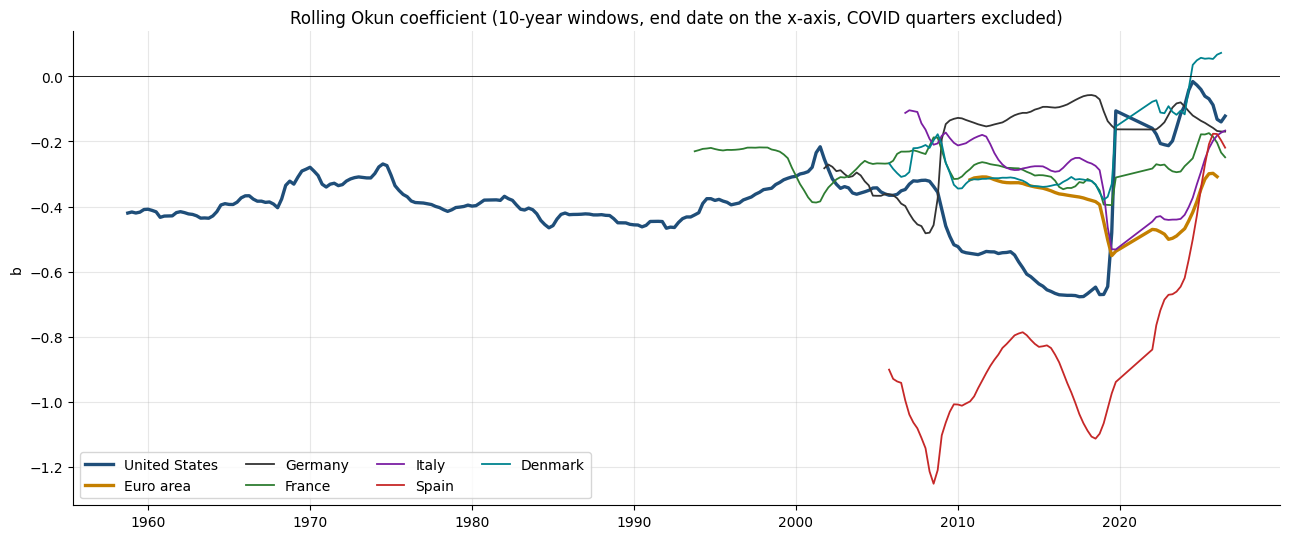

,b before 2008,s.e. before,start before,b after 2010,s.e. after,change
United States,-0.39,0.02,1949Q1,-0.06,0.16,0.33
Euro area,-0.44,0.05,2001Q1,-0.44,0.08,0.00
Germany,-0.40,0.06,1992Q1,-0.20,0.04,0.20
France,-0.26,0.06,1984Q1,-0.28,0.06,-0.02
Italy,-0.12,0.05,1997Q1,-0.43,0.10,-0.31
Spain,-0.88,0.25,1996Q1,-0.67,0.11,0.21
Denmark,-0.24,0.06,1996Q1,0.02,0.07,0.26


In [8]:
def rolling_okun(df, window=ROLLING_WINDOW):
    d = df.dropna(subset=["growth", "d_unemployment"])
    d = d[~d["covid"]]
    out = {}
    for i in range(window, len(d) + 1):
        w = d.iloc[i - window:i]
        b = np.polyfit(w["growth"], w["d_unemployment"], 1)[0]
        out[w.index[-1]] = b
    return pd.Series(out)


rolling = {name: rolling_okun(data[name]) for name in NAMES}

fig, ax = plt.subplots(figsize=(13, 5.5))
for name in NAMES:
    s = rolling[name]
    lw = 2.4 if name in ("United States", "Euro area") else 1.3
    ax.plot(s.index.to_timestamp(), s.values, color=COLORS[name], lw=lw, label=name)
ax.axhline(0, color="black", lw=0.6)
ax.set_title("Rolling Okun coefficient (10-year windows, end date on the x-axis, COVID quarters excluded)")
ax.set_ylabel("b")
ax.legend(ncol=4)
fig.tight_layout()
save(fig, "05_rolling_okun.png")
plt.show()

split = {}
for name in NAMES:
    pre = okun(data[name], start=data[name].dropna(subset=["growth", "d_unemployment"]).index[0], end=PRE_CRISIS_END)
    post = okun(data[name], start=POST_CRISIS_START)
    split[name] = {"b before 2008": pre["okun_b"], "s.e. before": pre["okun_b_se"], "start before": pre["start"],
                   "b after 2010": post["okun_b"], "s.e. after": post["okun_b_se"],
                   "change": post["okun_b"] - pre["okun_b"]}
split = pd.DataFrame(split).T
split.to_csv(f"{TAB}/okun_before_after_crisis.csv")
display(split)

## Step 5: Today's labour market

For the most recent quarters we compare the **actual** change in unemployment with the change Okun's law predicts given actual growth. The difference (the *residual*) is a useful diagnostic:

- **positive residual** → unemployment rose more (or fell less) than growth would imply: the labour market is **weaker** than GDP suggests;
- **negative residual** → unemployment is lower than growth would imply: firms are holding on to workers (**labour hoarding**), or labour supply is tight.

For a strategist, a persistent negative residual during a slowdown is a warning sign: if firms stop hoarding labour, unemployment can catch up quickly.

,latest quarter,unemployment rate (%),"growth, 4q (%)","change in unemployment, 4q (pp)",Okun-predicted change (pp),"residual, latest (pp)","residual, avg last 4q (pp)"
United States,2026Q3,4.13,2.04,-0.20,0.02,-0.22,0.16
Euro area,2026Q1,6.47,0.49,0.13,0.18,-0.04,0.06
Germany,2026Q3,4.07,1.24,0.27,-0.22,0.48,0.46
France,2026Q3,8.37,-0.07,0.53,0.41,0.12,0.43
Italy,2026Q3,6.20,0.75,0.33,-0.21,0.54,-0.08
Spain,2026Q3,10.23,2.63,-0.27,-0.55,0.29,0.04
Denmark,2026Q2,6.83,5.50,0.57,-0.71,1.28,0.86


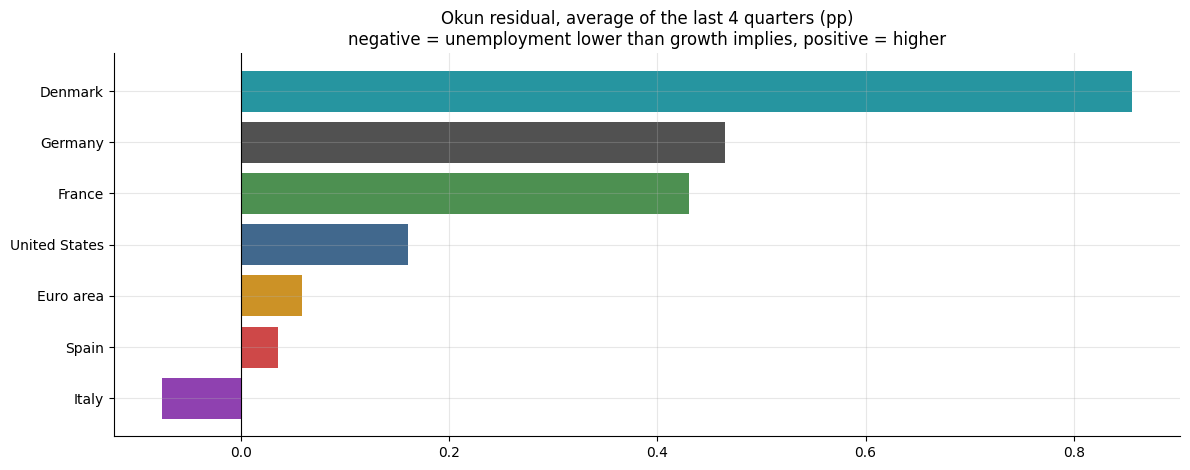

In [9]:
recent = {}
for name in NAMES:
    d = data[name].dropna(subset=["growth", "d_unemployment"])
    r = results[name]
    last = d.iloc[-4:]
    fitted = r["a"] + r["okun_b"] * last["growth"]
    recent[name] = {
        "latest quarter": str(d.index[-1]),
        "unemployment rate (%)": d["unemployment"].iloc[-1],
        "growth, 4q (%)": d["growth"].iloc[-1],
        "change in unemployment, 4q (pp)": d["d_unemployment"].iloc[-1],
        "Okun-predicted change (pp)": fitted.iloc[-1],
        "residual, latest (pp)": d["d_unemployment"].iloc[-1] - fitted.iloc[-1],
        "residual, avg last 4q (pp)": (last["d_unemployment"] - fitted).mean(),
    }
recent = pd.DataFrame(recent).T
recent.to_csv(f"{TAB}/current_labour_market.csv")
display(recent)

fig, ax = plt.subplots(figsize=(12, 4.8))
res = recent["residual, avg last 4q (pp)"].astype(float).sort_values()
ax.barh(res.index, res.values, color=[COLORS[n] for n in res.index], alpha=0.85)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Okun residual, average of the last 4 quarters (pp)\n"
             "negative = unemployment lower than growth implies, positive = higher")
fig.tight_layout()
save(fig, "06_current_residuals.png")
plt.show()

## Step 6: Scenarios

The most practical use of Okun's law: **translate a growth forecast into an unemployment forecast**. Each cell shows the change in the unemployment rate over the next four quarters implied by each country's estimated relationship, for a given growth outcome.

GDP growth over 4 quarters,-2%,-1%,+0%,+1%,+2%,+3%
Country,,,,,,
United States,2.07,1.57,1.06,0.55,0.04,-0.47
Euro area,1.09,0.72,0.36,-0.01,-0.38,-0.74
Germany,0.28,0.13,-0.02,-0.18,-0.33,-0.49
France,1.00,0.70,0.39,0.08,-0.23,-0.53
Italy,0.60,0.31,0.01,-0.28,-0.58,-0.88
Spain,3.02,2.25,1.48,0.70,-0.07,-0.84
Denmark,0.77,0.57,0.37,0.17,-0.02,-0.22


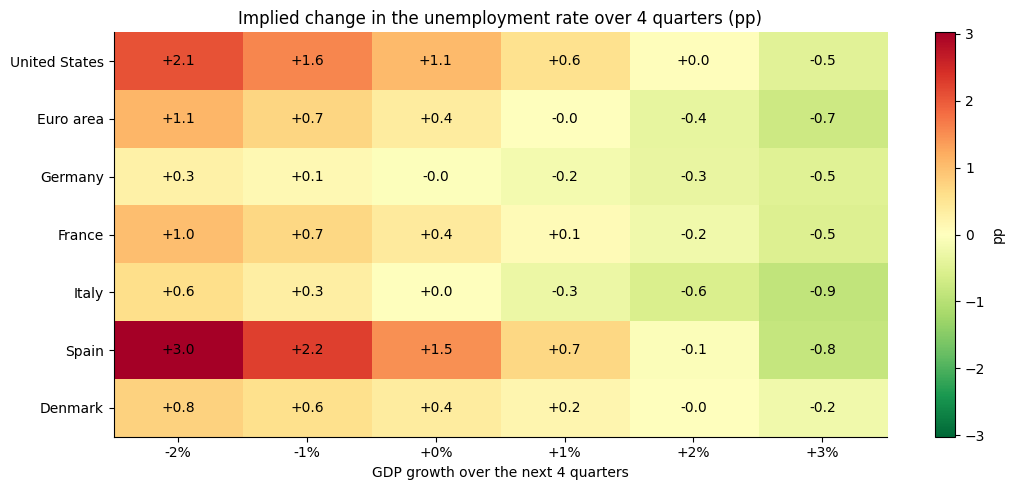

In [10]:
GROWTH_GRID = [-2.0, -1.0, 0.0, 1.0, 2.0, 3.0]
scen = pd.DataFrame({f"{g:+.0f}%": [results[n]["a"] + results[n]["okun_b"] * g for n in NAMES] for g in GROWTH_GRID},
                    index=NAMES)
scen.index.name, scen.columns.name = "Country", "GDP growth over 4 quarters"
scen.to_csv(f"{TAB}/scenarios.csv")
display(scen)

fig, ax = plt.subplots(figsize=(11, 5))
lim = np.nanmax(np.abs(scen.values))
im = ax.imshow(scen.values, cmap="RdYlGn_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(scen.shape[0]):
    for j in range(scen.shape[1]):
        ax.text(j, i, f"{scen.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=10)
ax.set_xticks(range(scen.shape[1]), scen.columns)
ax.set_yticks(range(scen.shape[0]), scen.index)
ax.set_xlabel("GDP growth over the next 4 quarters")
ax.grid(False)
fig.colorbar(im, ax=ax, label="pp")
ax.set_title("Implied change in the unemployment rate over 4 quarters (pp)")
fig.tight_layout()
save(fig, "07_scenarios.png")
plt.show()

## Step 7: Automatic export for GitHub

This cell writes a complete `README.md` with today's numbers and interpretation, adds `requirements.txt` and `.gitignore`, and zips everything with the charts and tables. In Colab the zip is downloaded automatically.

**What to upload to GitHub:** unzip the file and drag **all its contents, including the `figures` and `tables` folders as folders**, into *Add file → Upload files*. Then upload this notebook too (*File → Download → Download .ipynb*), saved **after** running it so that GitHub shows the outputs.

In [11]:
TODAY = date.today().strftime("%d %B %Y")


def fmt(v):
    if isinstance(v, (int, np.integer)):
        return str(v)
    if isinstance(v, (float, np.floating)):
        return f"{v:.2f}"
    return str(v)


def md_table(df):
    cols = [str(c) for c in df.columns]
    lines = ["| | " + " | ".join(cols) + " |", "|---|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        lines.append(f"| {idx} | " + " | ".join(fmt(v) for v in row) + " |")
    return "\n".join(lines)


ot = okun_table.copy()
for c in ["okun_b", "okun_b_se", "g_star", "g_star_se", "r2"]:
    ot[c] = ot[c].astype(float)
most, least = ot["okun_b"].idxmin(), ot["okun_b"].idxmax()
us_b, ea_b = ot.loc["United States", "okun_b"], ot.loc["Euro area", "okun_b"] if "Euro area" in ot.index else np.nan

coef_md = ot[["quarters", "okun_b", "okun_b_se", "g_star", "g_star_se", "r2"]].copy()
coef_md["quarters"] = coef_md["quarters"].astype(int)
coef_md.columns = ["Quarters", "Okun b", "s.e.", "Stable-unemployment growth g* (%)", "s.e.", "R²"]

coef_text = (
    f"Unemployment is most sensitive to growth in **{most}** (b = {ot.loc[most, 'okun_b']:.2f}) and least sensitive in "
    f"**{least}** (b = {ot.loc[least, 'okun_b']:.2f}). In the United States one extra point of growth lowers "
    f"unemployment by about {abs(us_b):.2f} pp over a year"
    + (f", against {abs(ea_b):.2f} pp in the euro area. " if not np.isnan(ea_b) else ". ")
    + "These differences mainly reflect **labour-market institutions**: where employment protection is lower or "
    "temporary contracts are widespread, firms adjust to a downturn by cutting jobs, so unemployment reacts strongly. "
    "Where firms adjust hours instead of headcount, for example through short-time work schemes such as Germany's "
    "*Kurzarbeit*, or tend to hoard labour, unemployment reacts much less. The fit (R²) also tells us how much of the "
    "movement in unemployment growth alone can explain."
)

gstar_text = (
    "The growth rate that keeps unemployment stable, g*, is an approximate measure of each economy's potential growth: "
    + ", ".join(f"{n} {ot.loc[n, 'g_star']:.1f}%" for n in ot.sort_values('g_star', ascending=False).index)
    + ". Growth below these rates tends to push unemployment up."
)

gap_text = (
    f"In the US, the unemployment gap moves by **{gap_beta:.2f} pp** for each point of output gap (R² = {gap_r2:.2f}). "
    + ("This is close to Okun's original rule of thumb of about −0.5, " if -0.65 <= gap_beta <= -0.35
       else "This differs from Okun's original rule of thumb of about −0.5, ")
    + "and it allows the monthly unemployment rate to be used as a real-time indicator of the output gap."
)

sp = split.copy()
for c in ["b before 2008", "s.e. before", "b after 2010", "s.e. after", "change"]:
    sp[c] = sp[c].astype(float)
more_sensitive = [n for n in NAMES if sp.loc[n, "change"] < -0.05]
less_sensitive = [n for n in NAMES if sp.loc[n, "change"] > 0.05]
stab_text = "Comparing the period before 2008 with the period after 2010: "
if more_sensitive:
    stab_text += "unemployment became **more sensitive** to growth in " + ", ".join(more_sensitive) + "; "
if less_sensitive:
    stab_text += "it became **less sensitive** in " + ", ".join(less_sensitive) + "; "
stable = [n for n in NAMES if n not in more_sensitive + less_sensitive]
if stable:
    stab_text += "it was broadly unchanged in " + ", ".join(stable) + "; "
stab_text = stab_text.rstrip("; ") + ". Coefficients estimated on short samples are imprecise, so small changes should not be over-interpreted."
split_md = sp[["start before", "b before 2008", "s.e. before", "b after 2010", "s.e. after", "change"]]

rc = recent.copy()
for c in rc.columns[1:]:
    rc[c] = rc[c].astype(float)
weaker = [n for n in NAMES if rc.loc[n, "residual, avg last 4q (pp)"] > 0.2]
tighter = [n for n in NAMES if rc.loc[n, "residual, avg last 4q (pp)"] < -0.2]
current_text = "Over the last four quarters, "
if tighter:
    current_text += ("unemployment has been **lower than growth would imply** in " + ", ".join(tighter)
                     + ": firms are hoarding labour or labour supply is tight, which leaves room for unemployment to "
                     "catch up if growth weakens; ")
if weaker:
    current_text += ("unemployment has been **higher than growth would imply** in " + ", ".join(weaker)
                     + ": the labour market is weaker than GDP suggests; ")
normal = [n for n in NAMES if n not in tighter + weaker]
if normal:
    current_text += "it has been **in line** with Okun's law in " + ", ".join(normal) + "; "
current_text = current_text.rstrip("; ") + "."
recent_md = rc[["latest quarter", "unemployment rate (%)", "growth, 4q (%)", "change in unemployment, 4q (pp)",
                "Okun-predicted change (pp)", "residual, avg last 4q (pp)"]]

summary = (
    f"Across seven economies, one extra point of GDP growth lowers unemployment by between "
    f"{abs(ot['okun_b'].max()):.2f} pp ({least}) and {abs(ot['okun_b'].min()):.2f} pp ({most}) over a year. "
    f"In the US the gap version gives a coefficient of {gap_beta:.2f}. "
    + (f"Today unemployment looks low relative to growth in {', '.join(tighter)}. " if tighter else "")
    + (f"It looks high relative to growth in {', '.join(weaker)}. " if weaker else "")
)

badge = f"https://colab.research.google.com/github/{GITHUB_USERNAME}/{REPO_NAME}/blob/main/{NOTEBOOK_NAME}"

readme = f"""# Okun's Law Across Countries

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)]({badge})

**Author:** {AUTHOR}
**Last updated:** {TODAY} (numbers and charts are generated automatically by the notebook)

## Summary

{summary}

## Research question

How much does unemployment respond to economic growth in the US and in Europe? Has this relationship changed over time, and is today's labour market behaving as growth would imply?

Okun's law is a standard tool for macro strategists and central banks: it translates GDP forecasts into unemployment forecasts, provides a real-time proxy for the output gap, and flags when the labour market diverges from the business cycle.

## Okun's law

Two versions are estimated:

**Difference version** (all countries):

$$\\Delta u_t = a + b\\, g_t + \\varepsilon_t$$

where $\\Delta u_t$ is the change in the unemployment rate over four quarters and $g_t$ real GDP growth over four quarters. $b$ is the **Okun coefficient**, and $g^* = -a/b$ is the growth rate that keeps unemployment stable.

**Gap version** (United States):

$$u_t - u^*_t = \\beta\\,(y_t - y^*_t) + \\varepsilon_t$$

linking the unemployment gap to the output gap, both from the Congressional Budget Office.

## Data

| Variable | United States | Europe |
|---|---|---|
| Real GDP | FRED (BEA) | Eurostat via FRED, ECB Data Portal as backup |
| Unemployment rate | FRED (BLS) | ECB Data Portal (Eurostat harmonised rate, age 15-74) |
| Potential GDP, natural rate | CBO via FRED | |

Countries: United States, euro area, Germany, France, Italy, Spain, Denmark. Quarterly data, seasonally adjusted. Estimation sample from {SAMPLE_START}, **excluding 2020-2021**, when COVID-related swings in GDP and job-retention schemes broke the usual relationship. Standard errors are HAC-robust.

## Results

### 1. Growth and unemployment

![Growth and unemployment](figures/01_growth_and_unemployment.png)

### 2. Okun's law by country

![Okun scatter](figures/02_okun_scatter.png)

![Okun coefficients](figures/03_okun_coefficients.png)

{md_table(coef_md)}

{coef_text}

{gstar_text}

### 3. Gap version (United States)

![US gap version](figures/04_us_gap_version.png)

{gap_text}

### 4. Stability over time

![Rolling Okun coefficient](figures/05_rolling_okun.png)

{md_table(split_md)}

{stab_text}

### 5. Today's labour market

![Current residuals](figures/06_current_residuals.png)

{md_table(recent_md)}

{current_text}

### 6. Scenarios

![Scenarios](figures/07_scenarios.png)

Implied change in the unemployment rate over four quarters (pp) for different growth outcomes:

{md_table(scen)}

## Limitations

- **Okun's law is a statistical regularity, not a structural model.** It summarises how firms, workers and institutions have reacted in the past, and can change when those change.
- **Data revisions.** GDP is revised substantially after its first release, while unemployment is rarely revised; real-time estimates would be weaker.
- **Labour supply.** Changes in participation, migration or demographics move unemployment independently of growth.
- **Excluding COVID** is a judgement call: it keeps the normal relationship clean but ignores how job-retention schemes changed labour-market adjustment.
- **Potential growth is not constant.** A single g* over 25 years averages across periods with different productivity and labour-force growth.

## Possible extensions

- Asymmetry: does unemployment rise faster in recessions than it falls in recoveries?
- Hours worked and employment instead of unemployment, to separate the intensive and extensive margins
- Time-varying coefficients with a state-space model (Kalman filter)
- Combining with the Sahm rule to build a real-time recession signal

## How to run

**Google Colab (recommended):** click the "Open in Colab" badge above, then *Runtime → Run all*.

**Locally:**
```bash
git clone https://github.com/{GITHUB_USERNAME}/{REPO_NAME}.git
cd {REPO_NAME}
pip install -r requirements.txt
jupyter notebook {NOTEBOOK_NAME}
```

## Repository structure

```
├── {NOTEBOOK_NAME}   # full analysis
├── figures/                     # charts generated by the notebook
├── tables/                      # results tables (CSV)
├── requirements.txt
└── README.md
```

## References

- Okun, A. M. (1962). Potential GNP: its measurement and significance. *Proceedings of the Business and Economic Statistics Section, American Statistical Association*, 98-104.
- Ball, L., Leigh, D. and Loungani, P. (2017). Okun's law: fit at 50? *Journal of Money, Credit and Banking*, 49(7), 1413-1441.
- Knotek, E. S. (2007). How useful is Okun's law? *Federal Reserve Bank of Kansas City Economic Review*, Q4, 73-103.

---

*Research and educational project. Not investment advice.*
"""

with open(f"{OUT}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)
with open(f"{OUT}/requirements.txt", "w") as f:
    f.write("pandas>=2.2\nnumpy\nmatplotlib\nstatsmodels\nrequests\njupyter\n")
with open(f"{OUT}/.gitignore", "w") as f:
    f.write("*.zip\n__pycache__/\n.ipynb_checkpoints/\n.venv/\n.DS_Store\n")

zip_path = shutil.make_archive(REPO_NAME, "zip", OUT)
print(f"Created {zip_path} with:")
for root, _, files in os.walk(OUT):
    for name in sorted(files):
        print("  ", os.path.relpath(os.path.join(root, name), OUT))

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not running in Colab: the zip file is in the current folder.")

Created /content/okun-law-analysis.zip with:
   .gitignore
   README.md
   requirements.txt
   figures/01_growth_and_unemployment.png
   figures/02_okun_scatter.png
   figures/03_okun_coefficients.png
   figures/04_us_gap_version.png
   figures/05_rolling_okun.png
   figures/06_current_residuals.png
   figures/07_scenarios.png
   tables/current_labour_market.csv
   tables/okun_before_after_crisis.csv
   tables/okun_coefficients.csv
   tables/okun_gap_version_us.csv
   tables/scenarios.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Preview of the generated README
from IPython.display import Markdown
Markdown(readme)

# Okun's Law Across Countries

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gabsmm18/okun-law-analysis/blob/main/okun_law_analysis.ipynb)

**Author:** Mattia Mariani
**Last updated:** 19 November 2026 (numbers and charts are generated automatically by the notebook)

## Summary

Across seven economies, one extra point of GDP growth lowers unemployment by between 0.15 pp (Germany) and 0.77 pp (Spain) over a year. In the US the gap version gives a coefficient of -0.82. It looks high relative to growth in Germany, France, Denmark. 

## Research question

How much does unemployment respond to economic growth in the US and in Europe? Has this relationship changed over time, and is today's labour market behaving as growth would imply?

Okun's law is a standard tool for macro strategists and central banks: it translates GDP forecasts into unemployment forecasts, provides a real-time proxy for the output gap, and flags when the labour market diverges from the business cycle.

## Okun's law

Two versions are estimated:

**Difference version** (all countries):

$$\Delta u_t = a + b\, g_t + \varepsilon_t$$

where $\Delta u_t$ is the change in the unemployment rate over four quarters and $g_t$ real GDP growth over four quarters. $b$ is the **Okun coefficient**, and $g^* = -a/b$ is the growth rate that keeps unemployment stable.

**Gap version** (United States):

$$u_t - u^*_t = \beta\,(y_t - y^*_t) + \varepsilon_t$$

linking the unemployment gap to the output gap, both from the Congressional Budget Office.

## Data

| Variable | United States | Europe |
|---|---|---|
| Real GDP | FRED (BEA) | Eurostat via FRED, ECB Data Portal as backup |
| Unemployment rate | FRED (BLS) | ECB Data Portal (Eurostat harmonised rate, age 15-74) |
| Potential GDP, natural rate | CBO via FRED | |

Countries: United States, euro area, Germany, France, Italy, Spain, Denmark. Quarterly data, seasonally adjusted. Estimation sample from 2000Q1, **excluding 2020-2021**, when COVID-related swings in GDP and job-retention schemes broke the usual relationship. Standard errors are HAC-robust.

## Results

### 1. Growth and unemployment

![Growth and unemployment](figures/01_growth_and_unemployment.png)

### 2. Okun's law by country

![Okun scatter](figures/02_okun_scatter.png)

![Okun coefficients](figures/03_okun_coefficients.png)

| | Quarters | Okun b | s.e. | Stable-unemployment growth g* (%) | s.e. | R² |
|---|---|---|---|---|---|---|
| Spain | 99.00 | -0.77 | 0.12 | 1.91 | 0.34 | 0.69 |
| United States | 99.00 | -0.51 | 0.09 | 2.08 | 0.27 | 0.51 |
| Euro area | 93.00 | -0.37 | 0.04 | 0.97 | 0.24 | 0.70 |
| France | 99.00 | -0.31 | 0.04 | 1.26 | 0.27 | 0.47 |
| Italy | 99.00 | -0.30 | 0.07 | 0.04 | 0.48 | 0.51 |
| Denmark | 98.00 | -0.20 | 0.08 | 1.88 | 0.70 | 0.24 |
| Germany | 99.00 | -0.15 | 0.07 | -0.16 | 1.23 | 0.24 |

Unemployment is most sensitive to growth in **Spain** (b = -0.77) and least sensitive in **Germany** (b = -0.15). In the United States one extra point of growth lowers unemployment by about 0.51 pp over a year, against 0.37 pp in the euro area. These differences mainly reflect **labour-market institutions**: where employment protection is lower or temporary contracts are widespread, firms adjust to a downturn by cutting jobs, so unemployment reacts strongly. Where firms adjust hours instead of headcount, for example through short-time work schemes such as Germany's *Kurzarbeit*, or tend to hoard labour, unemployment reacts much less. The fit (R²) also tells us how much of the movement in unemployment growth alone can explain.

The growth rate that keeps unemployment stable, g*, is an approximate measure of each economy's potential growth: United States 2.1%, Spain 1.9%, Denmark 1.9%, France 1.3%, Euro area 1.0%, Italy 0.0%, Germany -0.2%. Growth below these rates tends to push unemployment up.

### 3. Gap version (United States)

![US gap version](figures/04_us_gap_version.png)

In the US, the unemployment gap moves by **-0.82 pp** for each point of output gap (R² = 0.80). This differs from Okun's original rule of thumb of about −0.5, and it allows the monthly unemployment rate to be used as a real-time indicator of the output gap.

### 4. Stability over time

![Rolling Okun coefficient](figures/05_rolling_okun.png)

| | start before | b before 2008 | s.e. before | b after 2010 | s.e. after | change |
|---|---|---|---|---|---|---|
| United States | 1949Q1 | -0.39 | 0.02 | -0.06 | 0.16 | 0.33 |
| Euro area | 2001Q1 | -0.44 | 0.05 | -0.44 | 0.08 | 0.00 |
| Germany | 1992Q1 | -0.40 | 0.06 | -0.20 | 0.04 | 0.20 |
| France | 1984Q1 | -0.26 | 0.06 | -0.28 | 0.06 | -0.02 |
| Italy | 1997Q1 | -0.12 | 0.05 | -0.43 | 0.10 | -0.31 |
| Spain | 1996Q1 | -0.88 | 0.25 | -0.67 | 0.11 | 0.21 |
| Denmark | 1996Q1 | -0.24 | 0.06 | 0.02 | 0.07 | 0.26 |

Comparing the period before 2008 with the period after 2010: unemployment became **more sensitive** to growth in Italy; it became **less sensitive** in United States, Germany, Spain, Denmark; it was broadly unchanged in Euro area, France. Coefficients estimated on short samples are imprecise, so small changes should not be over-interpreted.

### 5. Today's labour market

![Current residuals](figures/06_current_residuals.png)

| | latest quarter | unemployment rate (%) | growth, 4q (%) | change in unemployment, 4q (pp) | Okun-predicted change (pp) | residual, avg last 4q (pp) |
|---|---|---|---|---|---|---|
| United States | 2026Q3 | 4.13 | 2.04 | -0.20 | 0.02 | 0.16 |
| Euro area | 2026Q1 | 6.47 | 0.49 | 0.13 | 0.18 | 0.06 |
| Germany | 2026Q3 | 4.07 | 1.24 | 0.27 | -0.22 | 0.46 |
| France | 2026Q3 | 8.37 | -0.07 | 0.53 | 0.41 | 0.43 |
| Italy | 2026Q3 | 6.20 | 0.75 | 0.33 | -0.21 | -0.08 |
| Spain | 2026Q3 | 10.23 | 2.63 | -0.27 | -0.55 | 0.04 |
| Denmark | 2026Q2 | 6.83 | 5.50 | 0.57 | -0.71 | 0.86 |

Over the last four quarters, unemployment has been **higher than growth would imply** in Germany, France, Denmark: the labour market is weaker than GDP suggests; it has been **in line** with Okun's law in United States, Euro area, Italy, Spain.

### 6. Scenarios

![Scenarios](figures/07_scenarios.png)

Implied change in the unemployment rate over four quarters (pp) for different growth outcomes:

| | -2% | -1% | +0% | +1% | +2% | +3% |
|---|---|---|---|---|---|---|
| United States | 2.07 | 1.57 | 1.06 | 0.55 | 0.04 | -0.47 |
| Euro area | 1.09 | 0.72 | 0.36 | -0.01 | -0.38 | -0.74 |
| Germany | 0.28 | 0.13 | -0.02 | -0.18 | -0.33 | -0.49 |
| France | 1.00 | 0.70 | 0.39 | 0.08 | -0.23 | -0.53 |
| Italy | 0.60 | 0.31 | 0.01 | -0.28 | -0.58 | -0.88 |
| Spain | 3.02 | 2.25 | 1.48 | 0.70 | -0.07 | -0.84 |
| Denmark | 0.77 | 0.57 | 0.37 | 0.17 | -0.02 | -0.22 |

## Limitations

- **Okun's law is a statistical regularity, not a structural model.** It summarises how firms, workers and institutions have reacted in the past, and can change when those change.
- **Data revisions.** GDP is revised substantially after its first release, while unemployment is rarely revised; real-time estimates would be weaker.
- **Labour supply.** Changes in participation, migration or demographics move unemployment independently of growth.
- **Excluding COVID** is a judgement call: it keeps the normal relationship clean but ignores how job-retention schemes changed labour-market adjustment.
- **Potential growth is not constant.** A single g* over 25 years averages across periods with different productivity and labour-force growth.

## Possible extensions

- Asymmetry: does unemployment rise faster in recessions than it falls in recoveries?
- Hours worked and employment instead of unemployment, to separate the intensive and extensive margins
- Time-varying coefficients with a state-space model (Kalman filter)
- Combining with the Sahm rule to build a real-time recession signal

## How to run

**Google Colab (recommended):** click the "Open in Colab" badge above, then *Runtime → Run all*.

**Locally:**
```bash
git clone https://github.com/gabsmm18/okun-law-analysis.git
cd okun-law-analysis
pip install -r requirements.txt
jupyter notebook okun_law_analysis.ipynb
```

## Repository structure

```
├── okun_law_analysis.ipynb   # full analysis
├── figures/                     # charts generated by the notebook
├── tables/                      # results tables (CSV)
├── requirements.txt
└── README.md
```

## References

- Okun, A. M. (1962). Potential GNP: its measurement and significance. *Proceedings of the Business and Economic Statistics Section, American Statistical Association*, 98-104.
- Ball, L., Leigh, D. and Loungani, P. (2017). Okun's law: fit at 50? *Journal of Money, Credit and Banking*, 49(7), 1413-1441.
- Knotek, E. S. (2007). How useful is Okun's law? *Federal Reserve Bank of Kansas City Economic Review*, Q4, 73-103.

---

*Research and educational project. Not investment advice.*
